#  Analisis Sentimen Ulasan Pengguna Aplikasi Super App Polri
## Perbandingan Algoritma Naïve Bayes vs Random Forest

---
**Alur Implementasi:**
1. Instalasi & Import Library
2. Scraping Data dari Google Play Store
3. Eksplorasi Data (EDA)
4. Pelabelan Data Sentimen
5. Text Preprocessing
6. Ekstraksi Fitur TF-IDF & Pembagian Data
7. Pelatihan Model Naïve Bayes
8. Pelatihan Model Random Forest
9. Evaluasi & Perbandingan Kedua Model
10. Cross-Validation 5-Fold (Kedua Model)
11. Hyperparameter Tuning (Kedua Model)
12. Visualisasi Distribusi Sentimen Hasil Akhir
13. Simpan Model & Prediksi Teks Baru
---

##  TAHAP 1 — Instalasi & Import Library

In [1]:
!pip install google-play-scraper -q
!pip install PySastrawi -q
!pip install nltk -q
!pip install scikit-learn pandas numpy matplotlib seaborn wordcloud joblib -q
!pip install imbalanced-learn -q
!pip install statsmodels -q
print(' Semua library berhasil diinstall!')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 4.5 MB/s eta 0:00:00
 Semua library berhasil diinstall!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, joblib, warnings
warnings.filterwarnings('ignore')

from google_play_scraper import reviews, Sort, app as gplay_app

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from wordcloud import WordCloud

nltk.download('punkt',     quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

print(f'   pandas  : {pd.__version__}')
print(f'   numpy   : {np.__version__}')
print(f'   sklearn : {__import__("sklearn").__version__}')

   pandas  : 2.2.2
   numpy   : 2.0.2
   sklearn : 1.6.1


##  TAHAP 2 — Scraping Data dari Google Play Store

In [3]:
APP_ID         = 'superapps.polri.presisi.presisi'
JUMLAH_ULASAN  = 3000

print(f' Memverifikasi APP ID: {APP_ID}')
try:
    detail = gplay_app(APP_ID, lang='id', country='id')
    print(f' Aplikasi ditemukan!')
    print(f'   Nama      : {detail["title"]}')
    print(f'   Developer : {detail["developer"]}')
    print(f'   Rating    : {detail["score"]:.2f} ')
    print(f'   Total ulasan: {detail["ratings"]:,}')
except Exception as e:
    print(f'  Tidak dapat memverifikasi: {e}')

 Memverifikasi APP ID: superapps.polri.presisi.presisi
 Aplikasi ditemukan!
   Nama      : Super App Polri
   Developer : Kepolisian Negara Republik Indonesia
   Rating    : 4.84 
   Total ulasan: 381,522


In [4]:
print(f' Scraping {JUMLAH_ULASAN} ulasan...')

hasil, _ = reviews(
    APP_ID, lang='id', country='id',
    sort=Sort.NEWEST, count=JUMLAH_ULASAN,
    filter_score_with=None
)

df_raw = pd.DataFrame(hasil)
kolom_map = {'userName':'nama_pengguna','score':'rating','content':'ulasan','at':'tanggal'}
df = df_raw[[k for k in kolom_map if k in df_raw.columns]].copy()
df.rename(columns=kolom_map, inplace=True)
df.to_csv('data_ulasan_polri_raw.csv', index=False, encoding='utf-8-sig')

print(f'\n Scraping selesai!')
print(f'   Total ulasan : {len(df):,}')
if 'tanggal' in df.columns:
    print(f'   Periode      : {df["tanggal"].min()} s/d {df["tanggal"].max()}')
print(f'   Disimpan ke  : data_ulasan_polri_raw.csv')
df.head()

 Scraping 3000 ulasan...

 Scraping selesai!
   Total ulasan : 3,000
   Periode      : 2026-06-16 17:33:59 s/d 2026-08-07 06:41:08
   Disimpan ke  : data_ulasan_polri_raw.csv


,nama_pengguna,rating,ulasan,tanggal
0,Pengguna Google,5,baik,2026-08-07 06:41:08
1,Pengguna Google,5,aplikasi sangat membantu sekali dan mempermuda...,2026-08-07 06:35:18
2,Pengguna Google,5,"proses sangat cepat,",2026-08-07 06:31:50
3,Pengguna Google,5,good,2026-08-07 06:30:16
4,Pengguna Google,5,Sangat membantu,2026-08-07 05:56:17


##  TAHAP 3 — Eksplorasi Data (EDA)

In [5]:
print('='*55)
print(' INFORMASI DATASET')
print('='*55)
print(f'  Jumlah ulasan  : {len(df):,}')
print(f'  Missing values :\n{df.isnull().sum().to_string(header=False)}')

rating_counts = df['rating'].value_counts().sort_index()
print(f'\n  Distribusi Rating:')
for r, c in rating_counts.items():
    bar = '█' * int(c / max(rating_counts.values) * 20)
    print(f'    ⭐{r} : {c:4d} ulasan  {bar}')

 INFORMASI DATASET
  Jumlah ulasan  : 3,000
  Missing values :
nama_pengguna    0
rating           0
ulasan           0
tanggal          0

  Distribusi Rating:
    ⭐1 :  470 ulasan  ████
    ⭐2 :   74 ulasan  
    ⭐3 :  111 ulasan  █
    ⭐4 :  199 ulasan  █
    ⭐5 : 2146 ulasan  ████████████████████


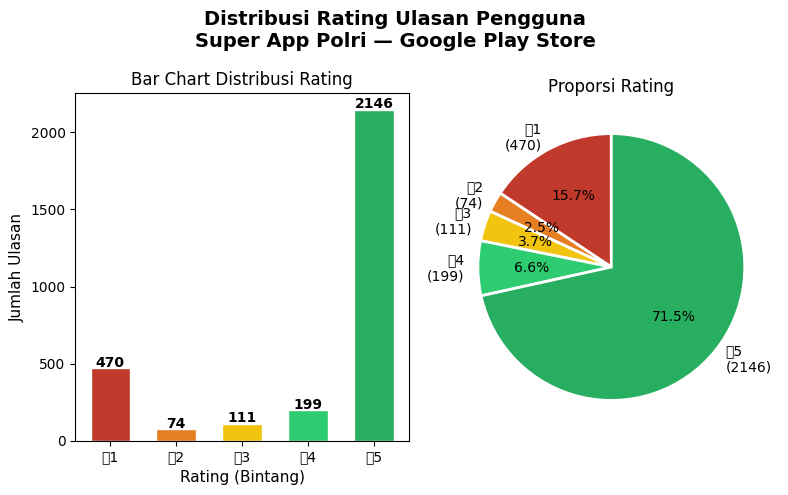

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 5))
fig.suptitle('Distribusi Rating Ulasan Pengguna\nSuper App Polri — Google Play Store',
             fontsize=14, fontweight='bold')
colors = ['#c0392b','#e67e22','#f1c40f','#2ecc71','#27ae60']

bars = axes[0].bar(rating_counts.index, rating_counts.values,
                   color=colors, edgecolor='white', width=0.6)
axes[0].set_xlabel('Rating (Bintang)', fontsize=11)
axes[0].set_ylabel('Jumlah Ulasan', fontsize=11)
axes[0].set_title('Bar Chart Distribusi Rating', fontsize=12)
axes[0].set_xticks([1,2,3,4,5])
axes[0].set_xticklabels(['⭐1','⭐2','⭐3','⭐4','⭐5'])
for bar, val in zip(bars, rating_counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+10, str(val),
                 ha='center', fontsize=10, fontweight='bold')

axes[1].pie(rating_counts.values,
            labels=[f'⭐{i}\n({v})' for i,v in rating_counts.items()],
            colors=colors, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Proporsi Rating', fontsize=12)

plt.tight_layout()
plt.savefig('distribusi_rating.png', dpi=150, bbox_inches='tight')
plt.show()


##  TAHAP 4 — Pelabelan Data Sentimen

| Rating | Label | Keterangan |
|--------|-------|------------|
| ⭐⭐⭐⭐⭐ (4-5) | **Positif** | Pengguna puas |
| ⭐⭐ (1-2) | **Negatif** | Pengguna tidak puas |
| ⭐⭐⭐ (3) | **Dihapus** | Ambigu, tidak digunakan |

In [7]:
def label_sentimen(rating):
    if rating >= 4:   return 'positif'
    elif rating <= 2: return 'negatif'
    else:             return 'hapus'

df['sentimen'] = df['rating'].apply(label_sentimen)
df_labeled = df[df['sentimen'] != 'hapus'].copy()
df_labeled = df_labeled[df_labeled['ulasan'].notna()]
df_labeled = df_labeled[df_labeled['ulasan'].str.strip() != '']
df_labeled.reset_index(drop=True, inplace=True)

sentimen_counts = df_labeled['sentimen'].value_counts()

print('='*55)
print('  HASIL PELABELAN SENTIMEN')
print('='*55)
print(f'  Data awal               : {len(df):,}')
print(f'  Dihapus (rating 3)      : {len(df[df["sentimen"]=="hapus"]):,}')
print(f'  Data setelah pelabelan  : {len(df_labeled):,}')
print(f'\n  Distribusi kelas:')
for s, c in sentimen_counts.items():
    print(f'    {s.upper():10s}: {c:,} ({c/len(df_labeled)*100:.1f}%)')

  HASIL PELABELAN SENTIMEN
  Data awal               : 3,000
  Dihapus (rating 3)      : 111
  Data setelah pelabelan  : 2,889

  Distribusi kelas:
    POSITIF   : 2,345 (81.2%)
    NEGATIF   : 544 (18.8%)


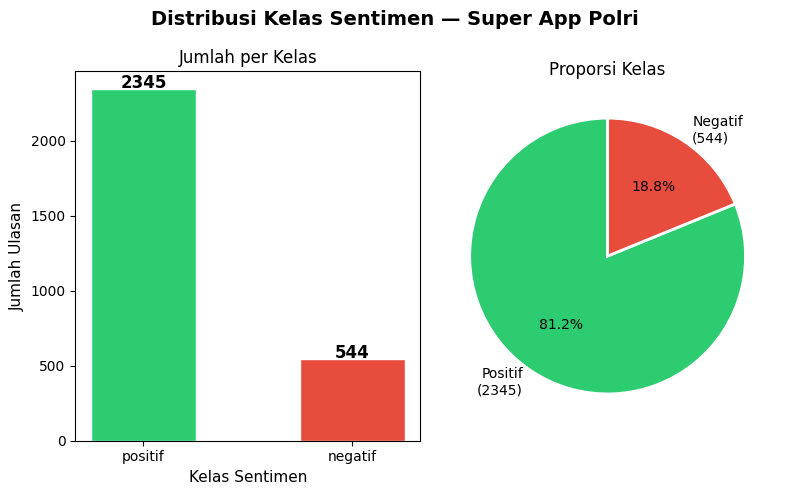

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 5))
fig.suptitle('Distribusi Kelas Sentimen — Super App Polri',
             fontsize=14, fontweight='bold')
warna = {'positif':'#2ecc71','negatif':'#e74c3c'}
bar_colors = [warna[s] for s in sentimen_counts.index]

bars = axes[0].bar(sentimen_counts.index, sentimen_counts.values,
                   color=bar_colors, edgecolor='white', width=0.5)
axes[0].set_title('Jumlah per Kelas', fontsize=12)
axes[0].set_xlabel('Kelas Sentimen', fontsize=11)
axes[0].set_ylabel('Jumlah Ulasan', fontsize=11)
for bar, val in zip(bars, sentimen_counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+5, str(val),
                 ha='center', fontsize=12, fontweight='bold')

axes[1].pie(sentimen_counts.values,
            labels=[f'{s.capitalize()}\n({c})' for s,c in sentimen_counts.items()],
            colors=bar_colors, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Proporsi Kelas', fontsize=12)

plt.tight_layout()
plt.savefig('distribusi_sentimen.png', dpi=150, bbox_inches='tight')
plt.show()


##  TAHAP 5 — Text Preprocessing

Pipeline: Case Folding -> Cleaning -> Normalisasi -> Tokenisasi -> Stopword Removal -> Stemming

In [9]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

stop_words = set(stopwords.words('indonesian'))
stop_words.update({
    'yg','dgn','utk','krn','sdh','jg','sy','nih',
    'aja','deh','sih','dong','lah','kah','tuh',
    'google','play','store','android','ios',
    'bapak','ibu','pak','bu','mas','mbak','kak',
    "nya", "sih", "deh", "dong", "kok", "lah"
})
kata_negasi = {
    'tidak','tak','bukan','belum','tanpa',
    'jangan','tiada','kurang'
}
stop_words = stop_words - kata_negasi

kamus_normalisasi = {
    'gak':'tidak','ga':'tidak','nggak':'tidak','ngga':'tidak',
    'gk':'tidak','tdk':'tidak','ndak':'tidak',
    'udah':'sudah','udh':'sudah','dah':'sudah','blm':'belum',
    'msh':'masih','masi':'masih',
    'emg':'memang','emang':'memang',
    'bgt':'banget','bngt':'banget',
    'bener':'benar','beneran':'benar',
    'tp':'tapi','tpi':'tapi',
    'klo':'kalau','klu':'kalau','kalo':'kalau',
    'lgi':'lagi','lg':'lagi',
    'krng':'kurang','krg':'kurang','bkn':'bukan',
    'gimana':'bagaimana','gmn':'bagaimana','knp':'kenapa',
    'oke':'baik','ok':'baik',
    'mantap':'bagus','mantul':'bagus','keren':'bagus',
    'susah':'sulit','payah':'buruk','parah':'buruk',
    'lelet':'lambat','lemot':'lambat','eror':'error',
    'loading':'memuat','update':'perbarui',
    'login':'masuk','logout':'keluar','hp':'ponsel',
}

print(' Tools preprocessing berhasil diinisialisasi!')
print(f'   Stopwords        : {len(stop_words)} kata')
print(f'   Kamus normalisasi: {len(kamus_normalisasi)} entri')
print(f'   Kata negasi aman : {sorted(kata_negasi)}')
print(f'   Cek "tidak" di stopwords: {"tidak" in stop_words} (harus False)')


 Tools preprocessing berhasil diinisialisasi!
   Stopwords        : 773 kata
   Kamus normalisasi: 48 entri
   Kata negasi aman : ['belum', 'bukan', 'jangan', 'kurang', 'tak', 'tanpa', 'tiada', 'tidak']
   Cek "tidak" di stopwords: False (harus False)


In [10]:
def case_folding(teks):
    """Ubah semua huruf menjadi huruf kecil."""
    return teks.lower()

def cleaning(teks):
    """Hapus URL, mention, hashtag, emoji, angka, tanda baca."""
    teks = re.sub(r'http\S+|www\S+', '', teks)
    teks = re.sub(r'@\w+', '', teks)
    teks = re.sub(r'#\w+', '', teks)
    teks = teks.encode('ascii','ignore').decode('ascii')
    teks = re.sub(r'\d+', '', teks)
    teks = re.sub(r'[^\w\s]', ' ', teks)
    teks = re.sub(r'\s+', ' ', teks).strip()
    return teks

def normalisasi(teks):
    """Ganti kata tidak baku ke kata baku."""
    return ' '.join([kamus_normalisasi.get(k, k) for k in teks.split()])

def tokenisasi(teks):
    """Pecah teks menjadi daftar token."""
    return word_tokenize(teks)

def hapus_stopword(tokens):
    """Hapus stopwords dan token terlalu pendek."""
    return [k for k in tokens if k not in stop_words and len(k) > 1]

def stemming(tokens):
    """Kembalikan kata ke bentuk dasar (PySastrawi).

    """
    hasil = []
    for k in tokens:
        if k in kata_negasi:
            hasil.append(k)  # Pertahankan kata negasi apa adanya
        else:
            hasil.append(stemmer.stem(k))
    return hasil

def preprocessing_lengkap(teks):
    """Pipeline preprocessing end-to-end."""
    if not isinstance(teks, str) or teks.strip() == '':
        return ''
    teks   = case_folding(teks)
    teks   = cleaning(teks)
    teks   = normalisasi(teks)
    tokens = tokenisasi(teks)
    tokens = hapus_stopword(tokens)
    tokens = stemming(tokens)
    return ' '.join(tokens)

print(' Demo preprocessing :')
contoh1 = "apk nya tidak bagus, gak banget deh"
contoh2 = "Aplikasi Polri GAK BISA login!! error terus, udah update masih aja error"
contoh3 = "Fitur SKCK online sangat membantu dan mudah digunakan"
contoh4 = "Tidak bisa login dari kemarin, sangat mengecewakan"
for c in [contoh1, contoh2, contoh3, contoh4]:
    print(f'  Input  : {c}')
    print(f'  Output : {preprocessing_lengkap(c)}')
    print()


 Demo preprocessing :
  Input  : apk nya tidak bagus, gak banget deh
  Output : apk tidak bagus tidak banget

  Input  : Aplikasi Polri GAK BISA login!! error terus, udah update masih aja error
  Output : aplikasi polri tidak masuk error baru error

  Input  : Fitur SKCK online sangat membantu dan mudah digunakan
  Output : fitur skck online bantu mudah

  Input  : Tidak bisa login dari kemarin, sangat mengecewakan
  Output : tidak masuk kemarin kecewa



In [11]:
df_labeled['ulasan_bersih'] = df_labeled['ulasan'].apply(preprocessing_lengkap)
df_labeled = df_labeled[df_labeled['ulasan_bersih'].str.strip() != '']
df_labeled.reset_index(drop=True, inplace=True)
df_labeled['jml_kata'] = df_labeled['ulasan_bersih'].apply(lambda x: len(x.split()))

print(f'   Data setelah preprocessing: {len(df_labeled):,} ulasan')
print(f'\n   Statistik panjang ulasan:')
print(df_labeled.groupby('sentimen')['jml_kata'].describe()[['mean','min','max']].round(1))

df_labeled.to_csv('data_ulasan_polri_preprocessed.csv', index=False, encoding='utf-8-sig')
print('\n   Disimpan: data_ulasan_polri_preprocessed.csv')
df_labeled[['ulasan','ulasan_bersih','sentimen']].head()

   Data setelah preprocessing: 2,556 ulasan

   Statistik panjang ulasan:
          mean  min   max
sentimen                 
negatif   10.9  1.0  71.0
positif    3.1  1.0  49.0

   Disimpan: data_ulasan_polri_preprocessed.csv


,ulasan,ulasan_bersih,sentimen
0,aplikasi sangat membantu sekali dan mempermuda...,aplikasi bantu mudah buat skck bagus,positif
1,"proses sangat cepat,",proses cepat,positif
2,good,good,positif
3,Sangat membantu,bantu,positif
4,mohon lebih dipermudahkan saat pengambilan fot...,mohon mudah ambil foto pakai layar gagal,positif


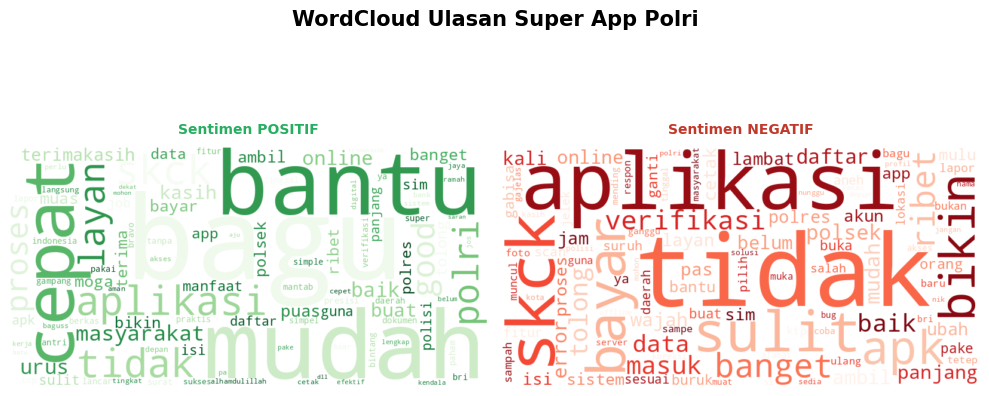

 WordCloud disimpan!


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle('WordCloud Ulasan Super App Polri', fontsize=15, fontweight='bold')

for ax, (sent, cmap, wj) in zip(axes, [
    ('positif','Greens','#27ae60'),
    ('negatif','Reds',  '#c0392b')
]):
    teks = ' '.join(df_labeled[df_labeled['sentimen']==sent]['ulasan_bersih'])
    if teks.strip():
        wc = WordCloud(width=800, height=400, background_color='white',
                       colormap=cmap, max_words=100, collocations=False).generate(teks)
        ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'Sentimen {sent.upper()}', fontsize=10,
                 fontweight='bold', color=wj, pad=10)

plt.tight_layout()
plt.savefig('wordcloud_sentimen.png', dpi=150, bbox_inches='tight')
plt.show()
print(' WordCloud disimpan!')

###  Frekuensi Kata Tertinggi per Kategori Sentimen

> WordCloud pada visualisasi sebelumnya merepresentasikan frekuensi kata secara visual (ukuran huruf). Sel berikut menghitung **frekuensi kata secara pasti** menggunakan `Counter` untuk melengkapi WordCloud dengan angka.

In [43]:
from collections import Counter

def top_kata(teks_series, n=15):
    semua_kata = ' '.join(teks_series).split()
    counter = Counter(semua_kata)
    return counter.most_common(n)

top_positif = top_kata(df_labeled[df_labeled['sentimen'] == 'positif']['ulasan_bersih'], n=15)
top_negatif = top_kata(df_labeled[df_labeled['sentimen'] == 'negatif']['ulasan_bersih'], n=15)

df_top_kata = pd.DataFrame({
    'Peringkat': range(1, 16),
    'Kata (Positif)': [k for k, _ in top_positif],
    'Frekuensi (Positif)': [f for _, f in top_positif],
    'Kata (Negatif)': [k for k, _ in top_negatif],
    'Frekuensi (Negatif)': [f for _, f in top_negatif],
})

print(' 15 Kata dengan Frekuensi Tertinggi per Kategori Sentimen:')
print(df_top_kata.to_string(index=False))


 15 Kata dengan Frekuensi Tertinggi per Kategori Sentimen:
 Peringkat Kata (Positif)  Frekuensi (Positif) Kata (Negatif)  Frekuensi (Negatif)
         1          bagus                  623          tidak                  380
         2          mudah                  391       aplikasi                  222
         3          bantu                  381           skck                  153
         4          cepat                  226          sulit                  107
         5       aplikasi                  163          bayar                   98
         6           skck                  162          bikin                   80
         7          tidak                  159            apk                   73
         8          layan                  123         banget                   69
         9          polri                  123          ribet                   68
        10           good                   97     verifikasi                   66
        11         proses   

In [14]:
X = df_labeled['ulasan_bersih']
y = df_labeled['sentimen']

# Split 80:20 dengan stratify — dipakai bersama kedua model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# TF-IDF: fit HANYA pada training data untuk menghindari data leakage
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print('='*55)
print('EKSTRAKSI FITUR TF-IDF & PEMBAGIAN DATA')
print('='*55)
print(f'  Total data          : {len(X):,} ulasan')
print(f'  Training (80%)      : {X_train_tfidf.shape[0]:,} ulasan')
print(f'  Testing  (20%)      : {X_test_tfidf.shape[0]:,} ulasan')
print(f'  Jumlah fitur TF-IDF : {X_train_tfidf.shape[1]:,}')
print(f'  ngram_range         : (1,2) — unigram & bigram')
print(f'\n  Kelas (train) : {dict(y_train.value_counts())}')
print(f'  Kelas (test)  : {dict(y_test.value_counts())}')

EKSTRAKSI FITUR TF-IDF & PEMBAGIAN DATA
  Total data          : 2,556 ulasan
  Training (80%)      : 2,044 ulasan
  Testing  (20%)      : 512 ulasan
  Jumlah fitur TF-IDF : 1,346
  ngram_range         : (1,2) — unigram & bigram

  Kelas (train) : {'positif': np.int64(1614), 'negatif': np.int64(430)}
  Kelas (test)  : {'positif': np.int64(404), 'negatif': np.int64(108)}


##  TAHAP 7 — Pelatihan Model Naïve Bayes

In [15]:

model_nb  = MultinomialNB(alpha=1.0)  # alpha=1.0 → Laplace Smoothing
model_nb.fit(X_train_tfidf, y_train)
y_pred_nb = model_nb.predict(X_test_tfidf)

akurasi_nb = accuracy_score(y_test, y_pred_nb)
presisi_nb = precision_score(y_test, y_pred_nb, average='weighted')
recall_nb  = recall_score(y_test, y_pred_nb, average='weighted')
f1_nb      = f1_score(y_test, y_pred_nb, average='weighted')

print('\n Naïve Bayes selesai dilatih')
print(f'   Akurasi  : {akurasi_nb*100:.2f}%')
print(f'   Presisi  : {presisi_nb*100:.2f}%')
print(f'   Recall   : {recall_nb*100:.2f}%')
print(f'   F1-Score : {f1_nb*100:.2f}%')
print(f'\n Classification Report Naïve Bayes:')
print(classification_report(y_test, y_pred_nb, target_names=['negatif','positif']))


 Naïve Bayes selesai dilatih
   Akurasi  : 91.41%
   Presisi  : 91.16%
   Recall   : 91.41%
   F1-Score : 91.11%

 Classification Report Naïve Bayes:
              precision    recall  f1-score   support

     negatif       0.86      0.71      0.78       108
     positif       0.93      0.97      0.95       404

    accuracy                           0.91       512
   macro avg       0.89      0.84      0.86       512
weighted avg       0.91      0.91      0.91       512



##  TAHAP 8 — Pelatihan Model Random Forest

In [16]:
print(' Melatih model Random Forest')

model_rf  = RandomForestClassifier(
    n_estimators=100,  # 100 pohon keputusan
    max_depth=None,    # Kedalaman tidak dibatasi
    random_state=42,   # Reprodusibilitas
    n_jobs=-1          # Pakai semua CPU core
)
model_rf.fit(X_train_tfidf, y_train)
y_pred_rf = model_rf.predict(X_test_tfidf)

akurasi_rf = accuracy_score(y_test, y_pred_rf)
presisi_rf = precision_score(y_test, y_pred_rf, average='weighted')
recall_rf  = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf      = f1_score(y_test, y_pred_rf, average='weighted')

print(' Random Forest selesai dilatih!')
print(f'   Akurasi  : {akurasi_rf*100:.2f}%')
print(f'   Presisi  : {presisi_rf*100:.2f}%')
print(f'   Recall   : {recall_rf*100:.2f}%')
print(f'   F1-Score : {f1_rf*100:.2f}%')
print(f'\n Classification Report Random Forest:')
print(classification_report(y_test, y_pred_rf, target_names=['negatif','positif']))

 Melatih model Random Forest
 Random Forest selesai dilatih!
   Akurasi  : 92.19%
   Presisi  : 92.14%
   Recall   : 92.19%
   F1-Score : 92.16%

 Classification Report Random Forest:
              precision    recall  f1-score   support

     negatif       0.82      0.81      0.81       108
     positif       0.95      0.95      0.95       404

    accuracy                           0.92       512
   macro avg       0.88      0.88      0.88       512
weighted avg       0.92      0.92      0.92       512



## TAHAP 9 — Evaluasi & Perbandingan Kedua Model

In [17]:
# Tabel perbandingan
df_comp = pd.DataFrame({
    'Metrik'            : ['Akurasi','Presisi','Recall','F1-Score'],
    'Naïve Bayes (%)'   : [v*100 for v in [akurasi_nb,presisi_nb,recall_nb,f1_nb]],
    'Random Forest (%)' : [v*100 for v in [akurasi_rf,presisi_rf,recall_rf,f1_rf]],
})
df_comp['Selisih (RF-NB)'] = (df_comp['Random Forest (%)']-df_comp['Naïve Bayes (%)']).apply(lambda x: f'{x:+.2f}%')
df_comp['Unggul'] = df_comp.apply(
    lambda r: 'Random Forest' if r['Random Forest (%)']>r['Naïve Bayes (%)'] else 'Naïve Bayes', axis=1)

print('='*70)
print('TABEL PERBANDINGAN NAÏVE BAYES vs RANDOM FOREST')
print('='*70)
print(df_comp.to_string(index=False))
print('='*70)

pemenang = 'Random Forest' if akurasi_rf > akurasi_nb else 'Naïve Bayes'
acc_win  = max(akurasi_rf, akurasi_nb)*100
acc_lose = min(akurasi_rf, akurasi_nb)*100
print(f'\n PEMENANG: {pemenang} ({acc_win:.2f}% vs {acc_lose:.2f}%)')
print(f' Selisih akurasi: {abs(akurasi_rf-akurasi_nb)*100:.2f}%')

TABEL PERBANDINGAN NAÏVE BAYES vs RANDOM FOREST
  Metrik  Naïve Bayes (%)  Random Forest (%) Selisih (RF-NB)        Unggul
 Akurasi        91.406250          92.187500          +0.78% Random Forest
 Presisi        91.156694          92.137687          +0.98% Random Forest
  Recall        91.406250          92.187500          +0.78% Random Forest
F1-Score        91.109262          92.160638          +1.05% Random Forest

 PEMENANG: Random Forest (92.19% vs 91.41%)
 Selisih akurasi: 0.78%


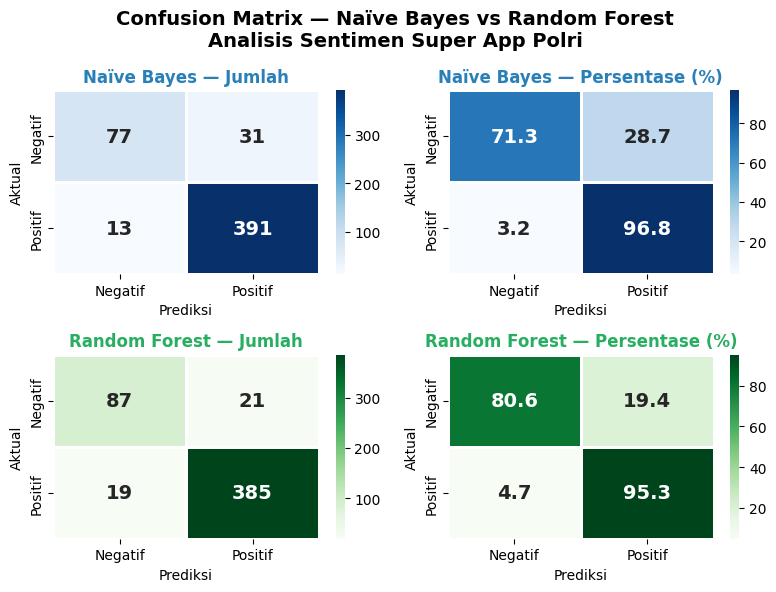

Komponen Confusion Matrix:
                          Naïve Bayes  Random Forest
   True Negative  (TN)             77             87
   False Positive (FP)             31             21
   False Negative (FN)             13             19
   True Positive  (TP)            391            385


In [18]:
# Confusion Matrix keempat panel
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=['negatif','positif'])
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=['negatif','positif'])
label_kelas = ['Negatif','Positif']

fig, axes = plt.subplots(2, 2, figsize=(8, 6))
fig.suptitle('Confusion Matrix — Naïve Bayes vs Random Forest\nAnalisis Sentimen Super App Polri',
             fontsize=14, fontweight='bold')

# NB Jumlah
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_kelas, yticklabels=label_kelas,
            ax=axes[0][0], linewidths=1, linecolor='white',
            annot_kws={'size':14,'weight':'bold'})
axes[0][0].set_title('Naïve Bayes — Jumlah', fontsize=12, fontweight='bold', color='#2980b9')
axes[0][0].set_xlabel('Prediksi'); axes[0][0].set_ylabel('Aktual')

# NB Persentase
cm_nb_pct = cm_nb.astype('float')/cm_nb.sum(axis=1)[:,np.newaxis]*100
sns.heatmap(cm_nb_pct, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=label_kelas, yticklabels=label_kelas,
            ax=axes[0][1], linewidths=1, linecolor='white',
            annot_kws={'size':14,'weight':'bold'})
axes[0][1].set_title('Naïve Bayes — Persentase (%)', fontsize=12, fontweight='bold', color='#2980b9')
axes[0][1].set_xlabel('Prediksi'); axes[0][1].set_ylabel('Aktual')

# RF Jumlah
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=label_kelas, yticklabels=label_kelas,
            ax=axes[1][0], linewidths=1, linecolor='white',
            annot_kws={'size':14,'weight':'bold'})
axes[1][0].set_title('Random Forest — Jumlah', fontsize=12, fontweight='bold', color='#27ae60')
axes[1][0].set_xlabel('Prediksi'); axes[1][0].set_ylabel('Aktual')

# RF Persentase
cm_rf_pct = cm_rf.astype('float')/cm_rf.sum(axis=1)[:,np.newaxis]*100
sns.heatmap(cm_rf_pct, annot=True, fmt='.1f', cmap='Greens',
            xticklabels=label_kelas, yticklabels=label_kelas,
            ax=axes[1][1], linewidths=1, linecolor='white',
            annot_kws={'size':14,'weight':'bold'})
axes[1][1].set_title('Random Forest — Persentase (%)', fontsize=12, fontweight='bold', color='#27ae60')
axes[1][1].set_xlabel('Prediksi'); axes[1][1].set_ylabel('Aktual')

plt.tight_layout()
plt.savefig('confusion_matrix_perbandingan.png', dpi=150, bbox_inches='tight')
plt.show()

TN_nb,FP_nb,FN_nb,TP_nb = cm_nb.ravel()
TN_rf,FP_rf,FN_rf,TP_rf = cm_rf.ravel()
print('Komponen Confusion Matrix:')
print(f'   {"":20s} {"Naïve Bayes":>13} {"Random Forest":>14}')
print(f'   {"True Negative  (TN)":20s} {TN_nb:>13} {TN_rf:>14}')
print(f'   {"False Positive (FP)":20s} {FP_nb:>13} {FP_rf:>14}')
print(f'   {"False Negative (FN)":20s} {FN_nb:>13} {FN_rf:>14}')
print(f'   {"True Positive  (TP)":20s} {TP_nb:>13} {TP_rf:>14}')

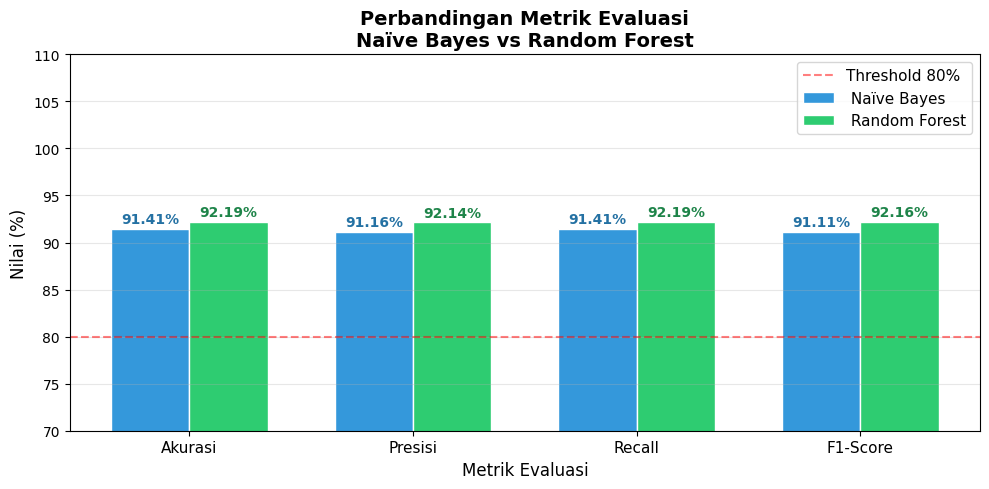

In [19]:
# Bar chart perbandingan metrik side-by-side
metrik_label = ['Akurasi','Presisi','Recall','F1-Score']
nilai_nb = [akurasi_nb, presisi_nb, recall_nb, f1_nb]
nilai_rf = [akurasi_rf, presisi_rf, recall_rf, f1_rf]
x     = np.arange(len(metrik_label))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars_nb = ax.bar(x-width/2, [v*100 for v in nilai_nb], width,
                 label=' Naïve Bayes', color='#3498db', edgecolor='white')
bars_rf = ax.bar(x+width/2, [v*100 for v in nilai_rf], width,
                 label=' Random Forest', color='#2ecc71', edgecolor='white')

for bar in bars_nb:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
            f'{bar.get_height():.2f}%', ha='center', va='bottom',
            fontsize=10, fontweight='bold', color='#2471a3')
for bar in bars_rf:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
            f'{bar.get_height():.2f}%', ha='center', va='bottom',
            fontsize=10, fontweight='bold', color='#1e8449')

ax.set_xlabel('Metrik Evaluasi', fontsize=12)
ax.set_ylabel('Nilai (%)', fontsize=12)
ax.set_title('Perbandingan Metrik Evaluasi\nNaïve Bayes vs Random Forest',
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrik_label, fontsize=11)
ax.set_ylim(70, 110)
ax.axhline(y=80, color='red', linestyle='--', alpha=0.5, label='Threshold 80%')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('perbandingan_metrik.png', dpi=150, bbox_inches='tight')
plt.show()


##  TAHAP 9.5 — Penanganan Ketidakseimbangan Kelas (Class Imbalance)

> Data memiliki rasio kelas ~67% positif : 33% negatif. Sebelum menerapkan solusi, kita cek dulu **classification_report per kelas** dari model baseline untuk melihat apakah kelas minoritas (negatif) benar-benar dirugikan. Kemudian dibandingkan dengan model yang sudah diberi pembobotan kelas (`class_weight` / `sample_weight`).

In [20]:
print(' Rasio kelas pada data training:')
rasio = y_train.value_counts(normalize=True) * 100
print(rasio.round(1))

print('\n' + '='*60)
print(' CLASSIFICATION REPORT PER KELAS — MODEL BASELINE')
print('='*60)
print('\n--- Naive Bayes (baseline, tanpa pembobotan) ---')
print(classification_report(y_test, y_pred_nb, target_names=['negatif','positif']))

print('--- Random Forest (baseline, tanpa pembobotan) ---')
print(classification_report(y_test, y_pred_rf, target_names=['negatif','positif']))

 Rasio kelas pada data training:
sentimen
positif    79.0
negatif    21.0
Name: proportion, dtype: float64

 CLASSIFICATION REPORT PER KELAS — MODEL BASELINE

--- Naive Bayes (baseline, tanpa pembobotan) ---
              precision    recall  f1-score   support

     negatif       0.86      0.71      0.78       108
     positif       0.93      0.97      0.95       404

    accuracy                           0.91       512
   macro avg       0.89      0.84      0.86       512
weighted avg       0.91      0.91      0.91       512

--- Random Forest (baseline, tanpa pembobotan) ---
              precision    recall  f1-score   support

     negatif       0.82      0.81      0.81       108
     positif       0.95      0.95      0.95       404

    accuracy                           0.92       512
   macro avg       0.88      0.88      0.88       512
weighted avg       0.92      0.92      0.92       512



In [21]:
# --- Solusi: pembobotan kelas (class_weight / sample_weight) ---
# MultinomialNB tidak punya parameter class_weight, jadi pakai sample_weight saat fit()
bobot_sampel_train = compute_sample_weight(class_weight='balanced', y=y_train)

model_nb_balanced = MultinomialNB(alpha=best_alpha if 'best_alpha' in dir() else 1.0)
model_nb_balanced.fit(X_train_tfidf, y_train, sample_weight=bobot_sampel_train)
y_pred_nb_balanced = model_nb_balanced.predict(X_test_tfidf)

# RandomForestClassifier punya parameter class_weight bawaan
model_rf_balanced = RandomForestClassifier(
    n_estimators=100, max_depth=None, random_state=42, n_jobs=-1,
    class_weight='balanced'
)
model_rf_balanced.fit(X_train_tfidf, y_train)
y_pred_rf_balanced = model_rf_balanced.predict(X_test_tfidf)

print('='*60)
print(' CLASSIFICATION REPORT PER KELAS — SETELAH PEMBOBOTAN KELAS')
print('='*60)
print('\n--- Naive Bayes (sample_weight=balanced) ---')
print(classification_report(y_test, y_pred_nb_balanced, target_names=['negatif','positif']))

print('--- Random Forest (class_weight=balanced) ---')
print(classification_report(y_test, y_pred_rf_balanced, target_names=['negatif','positif']))

 CLASSIFICATION REPORT PER KELAS — SETELAH PEMBOBOTAN KELAS

--- Naive Bayes (sample_weight=balanced) ---
              precision    recall  f1-score   support

     negatif       0.71      0.94      0.80       108
     positif       0.98      0.90      0.94       404

    accuracy                           0.90       512
   macro avg       0.84      0.92      0.87       512
weighted avg       0.92      0.90      0.91       512

--- Random Forest (class_weight=balanced) ---
              precision    recall  f1-score   support

     negatif       0.81      0.83      0.82       108
     positif       0.96      0.95      0.95       404

    accuracy                           0.92       512
   macro avg       0.88      0.89      0.89       512
weighted avg       0.92      0.92      0.92       512



In [22]:
# --- Tabel ringkas: dampak pembobotan kelas terhadap recall kelas NEGATIF (minoritas) ---
from sklearn.metrics import recall_score as _recall

ringkasan_imbalance = pd.DataFrame({
    'Model': ['Naive Bayes', 'Naive Bayes', 'Random Forest', 'Random Forest'],
    'Skenario': ['Baseline', 'sample_weight balanced', 'Baseline', 'class_weight balanced'],
    'Recall Negatif (%)': [
        _recall(y_test, y_pred_nb,          pos_label='negatif')*100,
        _recall(y_test, y_pred_nb_balanced, pos_label='negatif')*100,
        _recall(y_test, y_pred_rf,          pos_label='negatif')*100,
        _recall(y_test, y_pred_rf_balanced, pos_label='negatif')*100,
    ],
    'Akurasi Keseluruhan (%)': [
        accuracy_score(y_test, y_pred_nb)*100,
        accuracy_score(y_test, y_pred_nb_balanced)*100,
        accuracy_score(y_test, y_pred_rf)*100,
        accuracy_score(y_test, y_pred_rf_balanced)*100,
    ]
})
print(' Dampak pembobotan kelas terhadap deteksi kelas minoritas (negatif):')
print(ringkasan_imbalance.round(2).to_string(index=False))
print('\n Catatan interpretasi: jika Recall Negatif naik signifikan tanpa Akurasi Keseluruhan turun banyak,')
print('   berarti pembobotan kelas berhasil membuat model lebih adil ke kelas minoritas.')
print('   Sertakan tabel ini di BAB IV sebagai bagian pembahasan class imbalance.')

 Dampak pembobotan kelas terhadap deteksi kelas minoritas (negatif):
        Model               Skenario  Recall Negatif (%)  Akurasi Keseluruhan (%)
  Naive Bayes               Baseline               71.30                    91.41
  Naive Bayes sample_weight balanced               93.52                    90.43
Random Forest               Baseline               80.56                    92.19
Random Forest  class_weight balanced               83.33                    92.38

 Catatan interpretasi: jika Recall Negatif naik signifikan tanpa Akurasi Keseluruhan turun banyak,
   berarti pembobotan kelas berhasil membuat model lebih adil ke kelas minoritas.
   Sertakan tabel ini di BAB IV sebagai bagian pembahasan class imbalance.


###  SMOTE — Oversampling untuk Menyeimbangkan Kelas

> SMOTE (*Synthetic Minority Over-sampling Technique*) membuat sampel sintetis kelas minoritas (negatif) dengan cara interpolasi antar tetangga terdekat di ruang fitur TF-IDF, sehingga jumlah kelas negatif menjadi setara dengan kelas positif. **Penting:** SMOTE hanya diterapkan pada `X_train_tfidf` (data training) **setelah** split dan **setelah** TF-IDF di-fit — `X_test_tfidf` tidak disentuh sama sekali, supaya tidak ada data sintetis yang bocor ke proses evaluasi.

In [23]:
from imblearn.over_sampling import SMOTE

print(' Distribusi kelas SEBELUM SMOTE (data training):')
print(y_train.value_counts())

smote = SMOTE(random_state=42, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train_tfidf, y_train)

print('\n Distribusi kelas SETELAH SMOTE (data training):')
print(y_train_smote.value_counts())
print(f'\n   Jumlah data training bertambah dari {X_train_tfidf.shape[0]:,} menjadi {X_train_smote.shape[0]:,} baris')
print('   (X_test_tfidf dan y_test TIDAK diubah — tetap data asli untuk evaluasi yang valid)')

 Distribusi kelas SEBELUM SMOTE (data training):
sentimen
positif    1614
negatif     430
Name: count, dtype: int64

 Distribusi kelas SETELAH SMOTE (data training):
sentimen
positif    1614
negatif    1614
Name: count, dtype: int64

   Jumlah data training bertambah dari 2,044 menjadi 3,228 baris
   (X_test_tfidf dan y_test TIDAK diubah — tetap data asli untuk evaluasi yang valid)


In [24]:
# Latih ulang kedua model dengan data training hasil SMOTE, evaluasi tetap pada X_test_tfidf asli
model_nb_smote = MultinomialNB(alpha=best_alpha if 'best_alpha' in dir() else 1.0)
model_nb_smote.fit(X_train_smote, y_train_smote)
y_pred_nb_smote = model_nb_smote.predict(X_test_tfidf)

model_rf_smote = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1)
model_rf_smote.fit(X_train_smote, y_train_smote)
y_pred_rf_smote = model_rf_smote.predict(X_test_tfidf)

print('='*60)
print(' CLASSIFICATION REPORT PER KELAS — SETELAH SMOTE')
print('='*60)
print('\n--- Naive Bayes (training data di-SMOTE) ---')
print(classification_report(y_test, y_pred_nb_smote, target_names=['negatif','positif']))

print('--- Random Forest (training data di-SMOTE) ---')
print(classification_report(y_test, y_pred_rf_smote, target_names=['negatif','positif']))

 CLASSIFICATION REPORT PER KELAS — SETELAH SMOTE

--- Naive Bayes (training data di-SMOTE) ---
              precision    recall  f1-score   support

     negatif       0.64      0.95      0.76       108
     positif       0.99      0.85      0.92       404

    accuracy                           0.88       512
   macro avg       0.81      0.90      0.84       512
weighted avg       0.91      0.88      0.88       512

--- Random Forest (training data di-SMOTE) ---
              precision    recall  f1-score   support

     negatif       0.77      0.92      0.84       108
     positif       0.98      0.93      0.95       404

    accuracy                           0.93       512
   macro avg       0.88      0.92      0.90       512
weighted avg       0.93      0.93      0.93       512



In [25]:
# --- Tabel gabungan: Baseline vs class_weight balanced vs SMOTE ---
ringkasan_lengkap = pd.DataFrame({
    'Model': ['Naive Bayes']*3 + ['Random Forest']*3,
    'Skenario': ['Baseline', 'sample_weight/class_weight balanced', 'SMOTE (training di-oversample)']*2,
    'Recall Negatif (%)': [
        _recall(y_test, y_pred_nb,          pos_label='negatif')*100,
        _recall(y_test, y_pred_nb_balanced, pos_label='negatif')*100,
        _recall(y_test, y_pred_nb_smote,    pos_label='negatif')*100,
        _recall(y_test, y_pred_rf,          pos_label='negatif')*100,
        _recall(y_test, y_pred_rf_balanced, pos_label='negatif')*100,
        _recall(y_test, y_pred_rf_smote,    pos_label='negatif')*100,
    ],
    'Akurasi Keseluruhan (%)': [
        accuracy_score(y_test, y_pred_nb)*100,
        accuracy_score(y_test, y_pred_nb_balanced)*100,
        accuracy_score(y_test, y_pred_nb_smote)*100,
        accuracy_score(y_test, y_pred_rf)*100,
        accuracy_score(y_test, y_pred_rf_balanced)*100,
        accuracy_score(y_test, y_pred_rf_smote)*100,
    ],
    'F1-Score Negatif (%)': [
        f1_score(y_test, y_pred_nb,          pos_label='negatif')*100,
        f1_score(y_test, y_pred_nb_balanced, pos_label='negatif')*100,
        f1_score(y_test, y_pred_nb_smote,    pos_label='negatif')*100,
        f1_score(y_test, y_pred_rf,          pos_label='negatif')*100,
        f1_score(y_test, y_pred_rf_balanced, pos_label='negatif')*100,
        f1_score(y_test, y_pred_rf_smote,    pos_label='negatif')*100,
    ],
})
print(' Perbandingan lengkap: Baseline vs Class Weight vs SMOTE')
print(ringkasan_lengkap.round(2).to_string(index=False))
print('\n Pilih skenario dengan kombinasi Recall Negatif tertinggi dan Akurasi Keseluruhan yang tidak turun drastis')
print('   sebagai model final yang dilaporkan di BAB IV. Sertakan tabel ini utuh sebagai bukti eksperimen penanganan imbalance.')

 Perbandingan lengkap: Baseline vs Class Weight vs SMOTE
        Model                            Skenario  Recall Negatif (%)  Akurasi Keseluruhan (%)  F1-Score Negatif (%)
  Naive Bayes                            Baseline               71.30                    91.41                 77.78
  Naive Bayes sample_weight/class_weight balanced               93.52                    90.43                 80.48
  Naive Bayes      SMOTE (training di-oversample)               95.37                    87.50                 76.30
Random Forest                            Baseline               80.56                    92.19                 81.31
Random Forest sample_weight/class_weight balanced               83.33                    92.38                 82.19
Random Forest      SMOTE (training di-oversample)               91.67                    92.58                 83.90

 Pilih skenario dengan kombinasi Recall Negatif tertinggi dan Akurasi Keseluruhan yang tidak turun drastis
   sebagai model

##  TAHAP 10 — Cross-Validation 5-Fold (Kedua Model)

> Cross-validation membuktikan bahwa hasil tidak bergantung pada satu pembagian data saja.

In [26]:
print(' Cross-Validation 5-Fold untuk kedua model (BASELINE, sebelum tuning & penanganan imbalance):')
print(' Catatan: CV final (model tuned + imbalance handling) dihitung terpisah setelah TAHAP 11 —')
print('          lihat bagian "CV Model Final" sebelum Ringkasan Akhir.')

pipeline_nb = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)),
    ('nb',    MultinomialNB(alpha=1.0))
])
pipeline_rf = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)),
    ('rf',    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

metrik_cv = ['accuracy','precision_weighted','recall_weighted','f1_weighted']
label_cv  = ['Akurasi','Presisi','Recall','F1-Score']
cv_nb, cv_rf = {}, {}

for mk, lbl in zip(metrik_cv, label_cv):
    cv_nb[lbl] = cross_val_score(pipeline_nb, X, y, cv=5, scoring=mk)
    cv_rf[lbl] = cross_val_score(pipeline_rf, X, y, cv=5, scoring=mk)
    print(f'    {lbl} selesai')
print()

print(' HASIL CROSS-VALIDATION 5-FOLD')
print('='*75)
print(f'  {"Metrik":<10} {"Model":<16} {"F1":>7} {"F2":>7} {"F3":>7} {"F4":>7} {"F5":>7} {"Mean":>8} {"Std":>6}')
print('-'*75)
for lbl in label_cv:
    for nama, scores in [("Naïve Bayes", cv_nb[lbl]), ("Random Forest", cv_rf[lbl])]:
        print(f'  {lbl:<10} {nama:<16}',
              '  '.join([f'{s*100:.1f}%' for s in scores]),
              f'  {scores.mean()*100:.2f}%  {scores.std()*100:.2f}%')
    print()

 Cross-Validation 5-Fold untuk kedua model (BASELINE, sebelum tuning & penanganan imbalance):
 Catatan: CV final (model tuned + imbalance handling) dihitung terpisah setelah TAHAP 11 —
          lihat bagian "CV Model Final" sebelum Ringkasan Akhir.
    Akurasi selesai
    Presisi selesai
    Recall selesai
    F1-Score selesai

 HASIL CROSS-VALIDATION 5-FOLD
  Metrik     Model                 F1      F2      F3      F4      F5     Mean    Std
---------------------------------------------------------------------------
  Akurasi    Naïve Bayes      90.6%  91.6%  91.6%  90.4%  90.6%   90.96%  0.51%
  Akurasi    Random Forest    92.6%  92.2%  91.8%  90.4%  91.6%   91.71%  0.73%

  Presisi    Naïve Bayes      90.6%  91.5%  91.4%  90.2%  90.7%   90.89%  0.50%
  Presisi    Random Forest    92.4%  92.0%  91.9%  90.3%  92.1%   91.73%  0.73%

  Recall     Naïve Bayes      90.6%  91.6%  91.6%  90.4%  90.6%   90.96%  0.51%
  Recall     Random Forest    92.6%  92.2%  91.8%  90.4%  91.6%   91.71%  

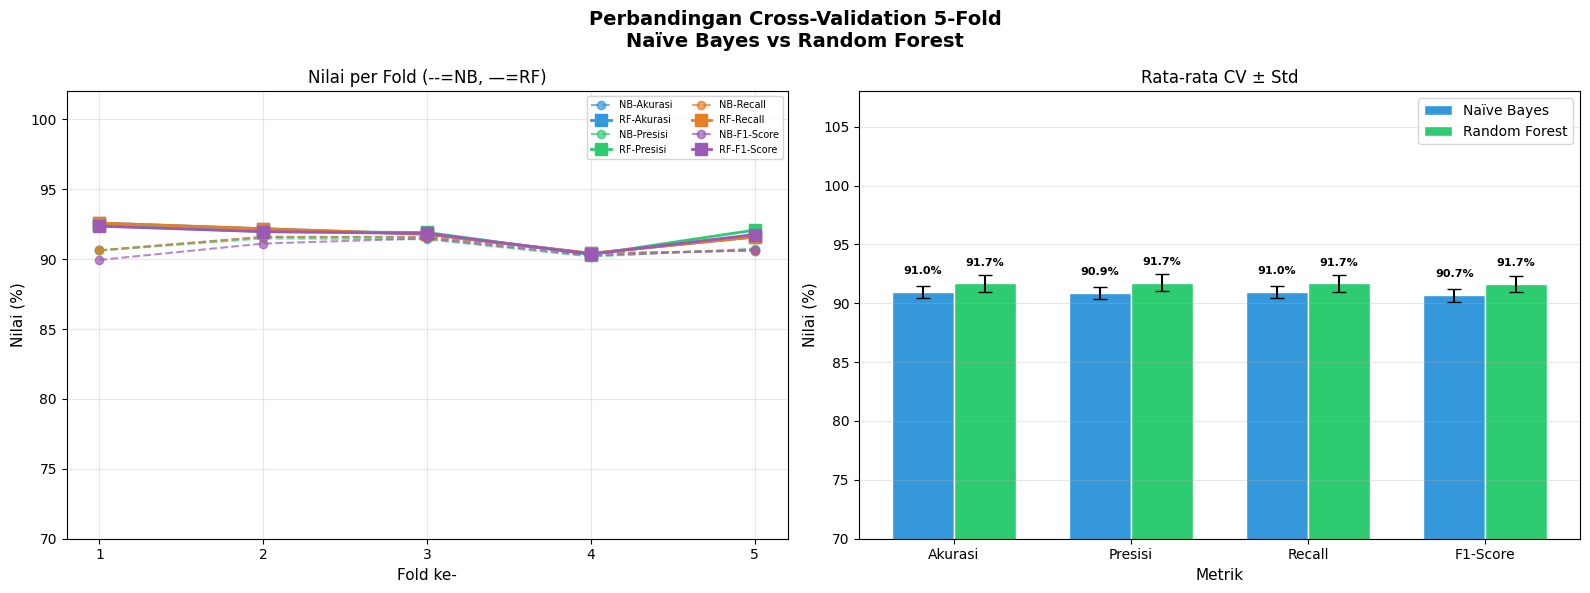

Grafik cross-validation disimpan!


In [27]:
# Visualisasi Cross-Validation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Perbandingan Cross-Validation 5-Fold\nNaïve Bayes vs Random Forest',
             fontsize=14, fontweight='bold')

warna_cv = ['#3498db','#2ecc71','#e67e22','#9b59b6']

# Panel kiri — garis per fold
for i, lbl in enumerate(label_cv):
    axes[0].plot(range(1,6), cv_nb[lbl]*100, 'o--', color=warna_cv[i],
                 linewidth=1.5, markersize=6, label=f'NB-{lbl}', alpha=0.7)
    axes[0].plot(range(1,6), cv_rf[lbl]*100, 's-',  color=warna_cv[i],
                 linewidth=2,   markersize=8, label=f'RF-{lbl}')
axes[0].set_title('Nilai per Fold (--=NB, —=RF)', fontsize=12)
axes[0].set_xlabel('Fold ke-', fontsize=11)
axes[0].set_ylabel('Nilai (%)', fontsize=11)
axes[0].set_xticks(range(1,6))
axes[0].set_ylim(70, 102)
axes[0].legend(fontsize=7, ncol=2)
axes[0].grid(True, alpha=0.3)

# Panel kanan — bar rata-rata dengan error bar
x2, w2 = np.arange(len(label_cv)), 0.35
means_nb = [cv_nb[l].mean()*100 for l in label_cv]
means_rf = [cv_rf[l].mean()*100 for l in label_cv]
stds_nb  = [cv_nb[l].std()*100  for l in label_cv]
stds_rf  = [cv_rf[l].std()*100  for l in label_cv]

b_nb = axes[1].bar(x2-w2/2, means_nb, w2, yerr=stds_nb,
                   color='#3498db', edgecolor='white', capsize=5, label='Naïve Bayes')
b_rf = axes[1].bar(x2+w2/2, means_rf, w2, yerr=stds_rf,
                   color='#2ecc71', edgecolor='white', capsize=5, label='Random Forest')
for bar in list(b_nb)+list(b_rf):
    axes[1].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+1.5,
                 f'{bar.get_height():.1f}%',
                 ha='center', fontsize=8, fontweight='bold')

axes[1].set_title('Rata-rata CV ± Std', fontsize=12)
axes[1].set_xlabel('Metrik', fontsize=11)
axes[1].set_ylabel('Nilai (%)', fontsize=11)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(label_cv)
axes[1].set_ylim(70, 108)
axes[1].legend(fontsize=10)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('cross_validation_perbandingan.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafik cross-validation disimpan!')

## TAHAP 11 — Hyperparameter Tuning (Kedua Model)

> Membuktikan secara empiris bahwa parameter yang digunakan adalah yang terbaik.

In [28]:
# GridSearch Naïve Bayes
print(' GridSearch Naïve Bayes (mencari alpha terbaik)')

gs_nb = GridSearchCV(
    Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)),
        ('nb',    MultinomialNB())
    ]),
    {'nb__alpha': [0.01,0.1,0.3,0.5,0.7,1.0,1.5,2.0,3.0,5.0]},
    cv=5, scoring='accuracy', n_jobs=-1
)
gs_nb.fit(X_train, y_train)  # FIX: hanya data training, X_test tidak boleh ikut proses tuning

best_alpha  = gs_nb.best_params_['nb__alpha']
best_acc_nb = gs_nb.best_score_

print(f'\n GridSearch Naïve Bayes selesai!')
print(f'   Alpha terbaik   : {best_alpha}')
print(f'   Akurasi terbaik : {best_acc_nb*100:.2f}%')
print(f'\n   Semua nilai alpha yang diuji:')
print(f'   {"Alpha":>8} | {"Akurasi CV":>12} | {"Selisih":>10}')
print(f'   {"-"*37}')
for a, s in zip(gs_nb.param_grid['nb__alpha'], gs_nb.cv_results_['mean_test_score']):
    mark = ' ← TERBAIK' if a==best_alpha else ''
    print(f'   {a:>8} | {s*100:>10.2f}% | {(s-best_acc_nb)*100:>+8.2f}%{mark}')

 GridSearch Naïve Bayes (mencari alpha terbaik)

 GridSearch Naïve Bayes selesai!
   Alpha terbaik   : 0.1
   Akurasi terbaik : 92.71%

   Semua nilai alpha yang diuji:
      Alpha |   Akurasi CV |    Selisih
   -------------------------------------
       0.01 |      92.51% |    -0.20%
        0.1 |      92.71% |    +0.00% ← TERBAIK
        0.3 |      92.51% |    -0.20%
        0.5 |      92.32% |    -0.39%
        0.7 |      92.12% |    -0.59%
        1.0 |      90.95% |    -1.76%
        1.5 |      90.17% |    -2.54%
        2.0 |      88.45% |    -4.26%
        3.0 |      84.98% |    -7.73%
        5.0 |      80.28% |   -12.43%


In [29]:
# GridSearch Random Forest
print('GridSearch Random Forest (mencari n_estimators & max_depth terbaik)...')

gs_rf = GridSearchCV(
    Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)),
        ('rf',    RandomForestClassifier(random_state=42, n_jobs=-1))
    ]),
    {
        'rf__n_estimators': [50, 100, 200],
        'rf__max_depth'   : [None, 10, 20],
    },
    cv=5, scoring='accuracy', n_jobs=-1, verbose=1
)
gs_rf.fit(X_train, y_train)  # FIX: hanya data training, X_test tidak boleh ikut proses tuning

best_n      = gs_rf.best_params_['rf__n_estimators']
best_depth  = gs_rf.best_params_['rf__max_depth']
best_acc_rf = gs_rf.best_score_

print(f'\n GridSearch Random Forest selesai!')
print(f'   n_estimators terbaik : {best_n}')
print(f'   max_depth terbaik    : {best_depth}')
print(f'   Akurasi terbaik      : {best_acc_rf*100:.2f}%')
print(f'\n   Semua kombinasi yang diuji:')
print(f'   {"n_est":>6} | {"max_depth":>10} | {"Akurasi CV":>12}')
print(f'   {"-"*34}')
for params, score in zip(gs_rf.cv_results_['params'], gs_rf.cv_results_['mean_test_score']):
    mark = ' ← TERBAIK' if (params['rf__n_estimators']==best_n and params['rf__max_depth']==best_depth) else ''
    print(f'   {params["rf__n_estimators"]:>6} | {str(params["rf__max_depth"]):>10} | {score*100:>10.2f}%{mark}')

GridSearch Random Forest (mencari n_estimators & max_depth terbaik)...
Fitting 5 folds for each of 9 candidates, totalling 45 fits

 GridSearch Random Forest selesai!
   n_estimators terbaik : 200
   max_depth terbaik    : None
   Akurasi terbaik      : 90.70%

   Semua kombinasi yang diuji:
    n_est |  max_depth |   Akurasi CV
   ----------------------------------
       50 |       None |      90.61%
      100 |       None |      90.66%
      200 |       None |      90.70% ← TERBAIK
       50 |         10 |      84.35%
      100 |         10 |      84.59%
      200 |         10 |      84.39%
       50 |         20 |      88.31%
      100 |         20 |      88.50%
      200 |         20 |      88.06%


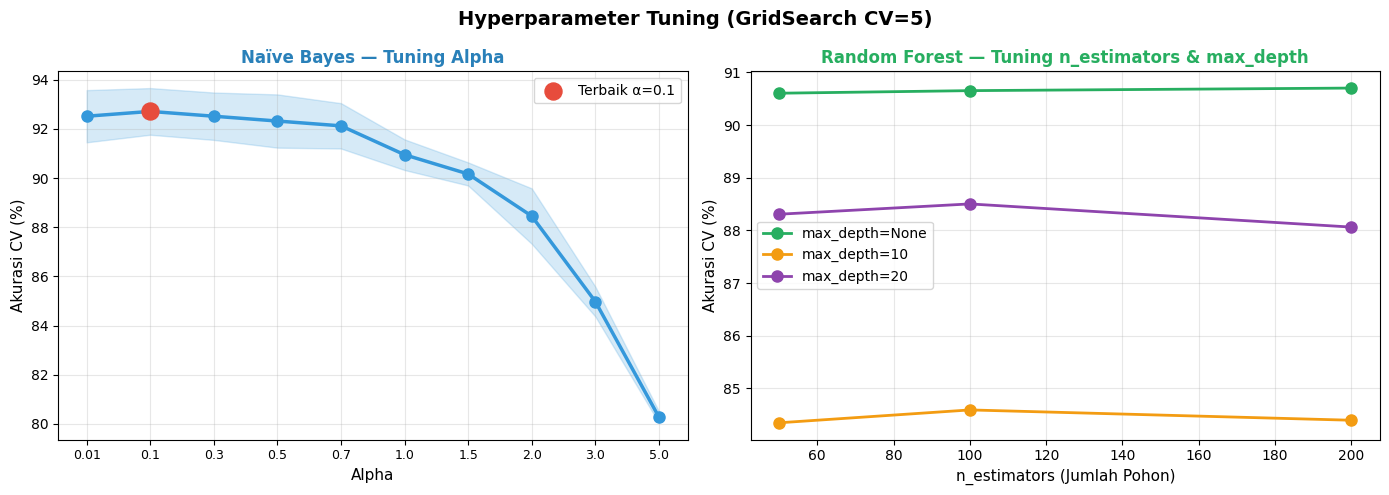

 Grafik GridSearch disimpan!


In [30]:
# Visualisasi GridSearch kedua model
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Hyperparameter Tuning (GridSearch CV=5)',
             fontsize=14, fontweight='bold')

# NB: alpha vs akurasi
alphas_list = gs_nb.param_grid['nb__alpha']
scores_nb   = gs_nb.cv_results_['mean_test_score']*100
stds_nb_gs  = gs_nb.cv_results_['std_test_score']*100
best_idx_nb = np.argmax(gs_nb.cv_results_['mean_test_score'])

axes[0].plot(range(len(alphas_list)), scores_nb, 'o-', color='#3498db',
             linewidth=2.5, markersize=8)
axes[0].fill_between(range(len(alphas_list)),
                     scores_nb-stds_nb_gs, scores_nb+stds_nb_gs,
                     alpha=0.2, color='#3498db')
axes[0].scatter(best_idx_nb, scores_nb[best_idx_nb], color='#e74c3c',
                s=150, zorder=5, label=f'Terbaik α={best_alpha}')
axes[0].set_xticks(range(len(alphas_list)))
axes[0].set_xticklabels(alphas_list, fontsize=9)
axes[0].set_xlabel('Alpha', fontsize=11)
axes[0].set_ylabel('Akurasi CV (%)', fontsize=11)
axes[0].set_title('Naïve Bayes — Tuning Alpha', fontsize=12, color='#2980b9', fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# RF: n_estimators vs akurasi per max_depth
warna_d = {'None':'#27ae60','10':'#f39c12','20':'#8e44ad'}
for dep in [None, 10, 20]:
    mask   = [p['rf__max_depth']==dep for p in gs_rf.cv_results_['params']]
    n_vals = [p['rf__n_estimators'] for p,m in zip(gs_rf.cv_results_['params'],mask) if m]
    sc     = [s*100 for s,m in zip(gs_rf.cv_results_['mean_test_score'],mask) if m]
    axes[1].plot(n_vals, sc, 'o-', linewidth=2, markersize=8,
                 color=warna_d[str(dep)], label=f'max_depth={dep}')

axes[1].set_xlabel('n_estimators (Jumlah Pohon)', fontsize=11)
axes[1].set_ylabel('Akurasi CV (%)', fontsize=11)
axes[1].set_title('Random Forest — Tuning n_estimators & max_depth',
                  fontsize=12, color='#27ae60', fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gridsearch_perbandingan.png', dpi=150, bbox_inches='tight')
plt.show()
print(' Grafik GridSearch disimpan!')

In [31]:
# LATIH ULANG MODEL FINAL — menggabungkan hyperparameter terbaik (GridSearch)
# DENGAN penanganan imbalance terbaik untuk masing-masing model (lihat TAHAP 9.5)
#
# Naive Bayes  -> alpha terbaik + sample_weight balanced
# Random Forest -> n_estimators/max_depth terbaik + class_weight='balanced'
#                  (Tabel perbandingan TAHAP 9.5 menunjukkan class_weight/sample_weight balanced
#                   memberikan hasil lebih baik dari SMOTE untuk KEDUA model pada eksperimen ini,
#                   sehingga strategi yang sama dipakai untuk NB maupun RF agar perbandingan konsisten)

# Naive Bayes terbaik (tuned alpha, dilatih dengan sample_weight balanced)
bobot_sampel_train_final = compute_sample_weight(class_weight='balanced', y=y_train)

model_nb_final = MultinomialNB(alpha=best_alpha)
model_nb_final.fit(X_train_tfidf, y_train, sample_weight=bobot_sampel_train_final)
y_pred_nb = model_nb_final.predict(X_test_tfidf)

akurasi_nb = accuracy_score(y_test, y_pred_nb)
presisi_nb = precision_score(y_test, y_pred_nb, average='weighted')
recall_nb  = recall_score(y_test, y_pred_nb, average='weighted')
f1_nb      = f1_score(y_test, y_pred_nb, average='weighted')

# Random Forest terbaik (tuned n_estimators/max_depth, class_weight='balanced')
model_rf_final = RandomForestClassifier(
    n_estimators=best_n,
    max_depth=best_depth,
    random_state=42, n_jobs=-1,
    class_weight='balanced'
)
model_rf_final.fit(X_train_tfidf, y_train)
y_pred_rf = model_rf_final.predict(X_test_tfidf)

akurasi_rf = accuracy_score(y_test, y_pred_rf)
presisi_rf = precision_score(y_test, y_pred_rf, average='weighted')
recall_rf  = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf      = f1_score(y_test, y_pred_rf, average='weighted')

# Ganti model lama — mulai baris ini, model_nb & model_rf merujuk ke MODEL FINAL
# (tuned + penanganan imbalance), dipakai otomatis di TAHAP 12 & 13 di bawah
model_nb = model_nb_final
model_rf = model_rf_final

print(f' Model final Naïve Bayes  → alpha={best_alpha} + sample_weight balanced | Akurasi: {akurasi_nb*100:.2f}%')
print(f' Model final Random Forest  → n_est={best_n}, depth={best_depth} + class_weight balanced | Akurasi: {akurasi_rf*100:.2f}%')
print()
print(classification_report(y_test, y_pred_nb, target_names=['negatif','positif']))
print(classification_report(y_test, y_pred_rf, target_names=['negatif','positif']))


 Model final Naïve Bayes  → alpha=0.1 + sample_weight balanced | Akurasi: 90.82%
 Model final Random Forest  → n_est=200, depth=None + class_weight balanced | Akurasi: 92.58%

              precision    recall  f1-score   support

     negatif       0.72      0.94      0.81       108
     positif       0.98      0.90      0.94       404

    accuracy                           0.91       512
   macro avg       0.85      0.92      0.88       512
weighted avg       0.93      0.91      0.91       512

              precision    recall  f1-score   support

     negatif       0.81      0.84      0.83       108
     positif       0.96      0.95      0.95       404

    accuracy                           0.93       512
   macro avg       0.89      0.90      0.89       512
weighted avg       0.93      0.93      0.93       512



###  Cross-Validation 5-Fold — Model Final (Tuned + Penanganan Imbalance)

> CV di TAHAP 10 dihitung dari model *baseline* (sebelum tuning, sebelum penanganan imbalance). CV di sini menghitung ulang khusus untuk **model final** yang benar-benar dipakai (NB: alpha tuned + sample_weight balanced, RF: hyperparameter tuned + class_weight balanced), supaya angka di Ringkasan Akhir konsisten dengan model yang sebenarnya dilaporkan.

In [32]:
# Pipeline NB final: TF-IDF -> MultinomialNB(alpha tuned), dievaluasi dengan sample_weight balanced
pipeline_nb_final = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)),
    ('nb',    MultinomialNB(alpha=best_alpha))
])

# Pipeline RF final: TF-IDF -> RandomForest(tuned, class_weight balanced)
pipeline_rf_final = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), min_df=2)),
    ('rf',    RandomForestClassifier(
        n_estimators=best_n, max_depth=best_depth,
        random_state=42, n_jobs=-1, class_weight='balanced'
    ))
])

# sample_weight dihitung dari seluruh y, cross_val_score otomatis mengiris array ini
# mengikuti indeks fold training/validasi yang sama seperti X dan y
bobot_sampel_cv = compute_sample_weight(class_weight='balanced', y=y)

cv_nb_final, cv_rf_final = {}, {}
print(' Menghitung Cross-Validation 5-Fold untuk MODEL FINAL...')
for mk, lbl in zip(metrik_cv, label_cv):
    cv_nb_final[lbl] = cross_val_score(
        pipeline_nb_final, X, y, cv=5, scoring=mk,
        params={'nb__sample_weight': bobot_sampel_cv}  # sklearn >=1.4: 'fit_params' diganti 'params'
    )
    cv_rf_final[lbl] = cross_val_score(pipeline_rf_final, X, y, cv=5, scoring=mk)
    print(f'    {lbl} selesai')

print('\n HASIL CROSS-VALIDATION — MODEL FINAL:')
for lbl in label_cv:
    print(f'   {lbl:<10} NB: {cv_nb_final[lbl].mean()*100:.2f}% ± {cv_nb_final[lbl].std()*100:.2f}%'
          f'   |   RF: {cv_rf_final[lbl].mean()*100:.2f}% ± {cv_rf_final[lbl].std()*100:.2f}%')


 Menghitung Cross-Validation 5-Fold untuk MODEL FINAL...
    Akurasi selesai
    Presisi selesai
    Recall selesai
    F1-Score selesai

 HASIL CROSS-VALIDATION — MODEL FINAL:
   Akurasi    NB: 90.22% ± 2.03%   |   RF: 91.74% ± 1.11%
   Presisi    NB: 92.37% ± 1.46%   |   RF: 91.88% ± 1.17%
   Recall     NB: 90.22% ± 2.03%   |   RF: 91.74% ± 1.11%
   F1-Score   NB: 90.72% ± 1.87%   |   RF: 91.76% ± 1.09%


###  Uji Signifikansi Statistik (McNemar Test) — Model Final

> Selisih akurasi NB vs RF (88.67% vs 92.38%) terlihat cukup besar, tapi untuk memastikan ini bukan kebetulan dari satu kali pembagian data, dilakukan uji McNemar terhadap prediksi `y_pred_nb` dan `y_pred_rf` (model final) pada test set yang sama.

In [33]:
from statsmodels.stats.contingency_tables import mcnemar

benar_nb = (y_pred_nb == y_test.values)
benar_rf = (y_pred_rf == y_test.values)

n_keduanya_benar    = int(( benar_nb &  benar_rf).sum())
n_nb_benar_rf_salah = int(( benar_nb & ~benar_rf).sum())
n_nb_salah_rf_benar = int((~benar_nb &  benar_rf).sum())
n_keduanya_salah    = int((~benar_nb & ~benar_rf).sum())

tabel_kontingensi = [
    [n_keduanya_benar,    n_nb_benar_rf_salah],
    [n_nb_salah_rf_benar, n_keduanya_salah]
]

print(' Tabel Kontingensi (NB vs RF, model final, pada test set yang sama):')
print(f'                      RF Benar    RF Salah')
print(f'   NB Benar          {n_keduanya_benar:>8}    {n_nb_benar_rf_salah:>8}')
print(f'   NB Salah          {n_nb_salah_rf_benar:>8}    {n_keduanya_salah:>8}')

n_diskordan = n_nb_benar_rf_salah + n_nb_salah_rf_benar
pakai_exact = n_diskordan < 25
hasil_mcnemar = mcnemar(tabel_kontingensi, exact=pakai_exact, correction=not pakai_exact)

print(f'\n Hasil McNemar Test:')
print(f'   Statistic  : {hasil_mcnemar.statistic:.4f}')
print(f'   p-value    : {hasil_mcnemar.pvalue:.4f}')
print(f'   Metode     : {"exact binomial" if pakai_exact else "chi-square dengan continuity correction"}')

alpha_sig = 0.05
if hasil_mcnemar.pvalue < alpha_sig:
    print(f'\n   Kesimpulan: p-value < {alpha_sig} → perbedaan performa NB vs RF SIGNIFIKAN secara statistik.')
else:
    print(f'\n   Kesimpulan: p-value >= {alpha_sig} → perbedaan performa NB vs RF TIDAK signifikan secara statistik')
    print(f'   (meskipun selisih akurasi terlihat besar, perlu kehati-hatian dalam mengklaim satu model "lebih baik").')

 Tabel Kontingensi (NB vs RF, model final, pada test set yang sama):
                      RF Benar    RF Salah
   NB Benar               451          14
   NB Salah                23          24

 Hasil McNemar Test:
   Statistic  : 1.7297
   p-value    : 0.1884
   Metode     : chi-square dengan continuity correction

   Kesimpulan: p-value >= 0.05 → perbedaan performa NB vs RF TIDAK signifikan secara statistik
   (meskipun selisih akurasi terlihat besar, perlu kehati-hatian dalam mengklaim satu model "lebih baik").


In [34]:
from sklearn.metrics import roc_auc_score

auc_nb = roc_auc_score(
    y_test,
    model_nb.predict_proba(X_test_tfidf)[:,1]
)

auc_rf = roc_auc_score(
    y_test,
    model_rf.predict_proba(X_test_tfidf)[:,1]
)

print("ROC-AUC NB :", auc_nb)
print("ROC-AUC RF :", auc_rf)

ROC-AUC NB : 0.9696323799046571
ROC-AUC RF : 0.9643151815181519


##  TAHAP 12 — Visualisasi Distribusi Sentimen Hasil Akhir

In [35]:
X_all = tfidf.transform(df_labeled['ulasan_bersih'])
df_labeled['pred_nb'] = model_nb.predict(X_all)
df_labeled['pred_rf'] = model_rf.predict(X_all)

dist_nb = df_labeled['pred_nb'].value_counts()
dist_rf = df_labeled['pred_rf'].value_counts()

print('='*60)
print('DISTRIBUSI PREDIKSI SELURUH DATA')
print('='*60)
print(f'  {"Sentimen":<12} {"Naïve Bayes":>16} {"Random Forest":>15}')
print(f'  {"-"*45}')
for s in ['positif','negatif']:
    c_nb = dist_nb.get(s,0)
    c_rf = dist_rf.get(s,0)
    print(f'  {s.capitalize():<12} {c_nb:>6} ({c_nb/len(df_labeled)*100:.1f}%)   {c_rf:>6} ({c_rf/len(df_labeled)*100:.1f}%)')
print(f'  {"Total":<12} {len(df_labeled):>6} (100.0%)  {len(df_labeled):>6} (100.0%)')

DISTRIBUSI PREDIKSI SELURUH DATA
  Sentimen          Naïve Bayes   Random Forest
  ---------------------------------------------
  Positif        1895 (74.1%)     2024 (79.2%)
  Negatif         661 (25.9%)      532 (20.8%)
  Total          2556 (100.0%)    2556 (100.0%)


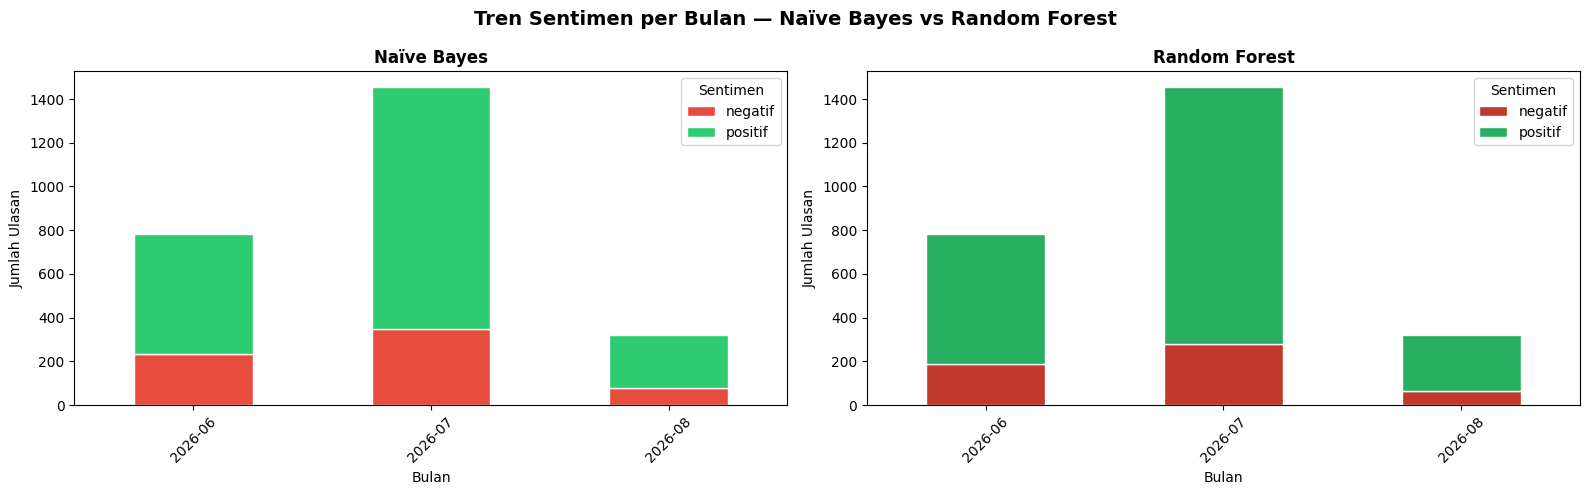

 Grafik tren bulanan disimpan!


In [36]:
if 'tanggal' in df_labeled.columns:
    df_labeled['tanggal']     = pd.to_datetime(df_labeled['tanggal'])
    df_labeled['bulan_tahun'] = df_labeled['tanggal'].dt.to_period('M')

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle('Tren Sentimen per Bulan — Naïve Bayes vs Random Forest',
                 fontsize=14, fontweight='bold')

    for ax, col, judul, wmap in [
        (axes[0],'pred_nb','Naïve Bayes',  {'positif':'#2ecc71','negatif':'#e74c3c'}),
        (axes[1],'pred_rf','Random Forest',{'positif':'#27ae60','negatif':'#c0392b'}),
    ]:
        monthly = df_labeled.groupby(['bulan_tahun',col]).size().unstack(fill_value=0)
        monthly.plot(kind='bar', stacked=True, ax=ax, color=wmap, edgecolor='white')
        ax.set_title(judul, fontsize=12, fontweight='bold')
        ax.set_xlabel('Bulan', fontsize=10)
        ax.set_ylabel('Jumlah Ulasan', fontsize=10)
        ax.legend(title='Sentimen')
        ax.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('tren_sentimen_bulanan.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(' Grafik tren bulanan disimpan!')

##  TAHAP 13 — Simpan Model & Prediksi Teks Baru

In [37]:
# model_nb & model_rf di titik ini adalah MODEL FINAL:
# hyperparameter terbaik (GridSearch) + penanganan imbalance (NB: sample_weight balanced, RF: class_weight balanced)
joblib.dump(model_nb, 'model_naive_bayes.pkl')
joblib.dump(model_rf, 'model_random_forest.pkl')
joblib.dump(tfidf,    'tfidf_vectorizer.pkl')
df_labeled.to_csv('data_ulasan_polri_hasil_akhir.csv', index=False, encoding='utf-8-sig')

print(' Semua model & data berhasil disimpan!')
print('   model_naive_bayes.pkl    → Model Naïve Bayes final (alpha tuned + sample_weight balanced)')
print('   model_random_forest.pkl  → Model Random Forest final (n_estimators/max_depth tuned + class_weight balanced)')
print('   tfidf_vectorizer.pkl     → TF-IDF Vectorizer')
print('   data_ulasan_polri_hasil_akhir.csv')

 Semua model & data berhasil disimpan!
   model_naive_bayes.pkl    → Model Naïve Bayes final (alpha tuned + sample_weight balanced)
   model_random_forest.pkl  → Model Random Forest final (n_estimators/max_depth tuned + class_weight balanced)
   tfidf_vectorizer.pkl     → TF-IDF Vectorizer
   data_ulasan_polri_hasil_akhir.csv


In [38]:
def prediksi_kedua_model(teks_baru):
    """Memprediksi sentimen menggunakan kedua model sekaligus."""
    teks_bersih = preprocessing_lengkap(teks_baru)
    tfidf_vec   = tfidf.transform([teks_bersih])

    pred_nb  = model_nb.predict(tfidf_vec)[0]
    prob_nb  = model_nb.predict_proba(tfidf_vec)[0]
    pred_rf  = model_rf.predict(tfidf_vec)[0]
    prob_rf  = model_rf.predict_proba(tfidf_vec)[0]
    kelas    = model_nb.classes_
    sepakat  = 'SEPAKAT' if pred_nb==pred_rf else '  BERBEDA'

    print(f' Input      : {teks_baru}')
    print(f' Bersih     : {teks_bersih}')
    print(f'─'*55)
    print(f' Naïve Bayes  : {pred_nb.upper()} {"😊" if pred_nb=="positif" else "😠"}')
    for k,p in zip(kelas,prob_nb):
        print(f'   {k:10s}: {p*100:.1f}% {"█"*int(p*25)}')
    print(f' Random Forest: {pred_rf.upper()} {"😊" if pred_rf=="positif" else "😠"}')
    for k,p in zip(kelas,prob_rf):
        print(f'   {k:10s}: {p*100:.1f}% {"█"*int(p*25)}')
    print(f' Kesepakatan  : {sepakat}')
    print()

print('='*60)
print(' DEMO PREDIKSI KEDUA MODEL')
print('='*60)
demo = [
    'Aplikasi Polri sangat membantu, perpanjangan SIM online mudah!',
    'Tidak bisa login dari kemarin, error terus, sangat mengecewakan!',
    'Lemot banget, sering force close, tidak bisa digunakan.',
    'Fitur SKCK online cepat dan mudah, terima kasih Polri!',
]
for i, ul in enumerate(demo, 1):
    print(f'--- Contoh {i} ---')
    prediksi_kedua_model(ul)

 DEMO PREDIKSI KEDUA MODEL
--- Contoh 1 ---
 Input      : Aplikasi Polri sangat membantu, perpanjangan SIM online mudah!
 Bersih     : aplikasi polri bantu panjang sim online mudah
───────────────────────────────────────────────────────
 Naïve Bayes  : POSITIF 😊
   negatif   : 3.0% 
   positif   : 97.0% ████████████████████████
 Random Forest: POSITIF 😊
   negatif   : 20.0% █████
   positif   : 80.0% ████████████████████
 Kesepakatan  : SEPAKAT

--- Contoh 2 ---
 Input      : Tidak bisa login dari kemarin, error terus, sangat mengecewakan!
 Bersih     : tidak masuk kemarin error kecewa
───────────────────────────────────────────────────────
 Naïve Bayes  : NEGATIF 😠
   negatif   : 98.7% ████████████████████████
   positif   : 1.3% 
 Random Forest: NEGATIF 😠
   negatif   : 92.0% ███████████████████████
   positif   : 8.0% ██
 Kesepakatan  : SEPAKAT

--- Contoh 3 ---
 Input      : Lemot banget, sering force close, tidak bisa digunakan.
 Bersih     : lambat banget force close tidak
──────

In [41]:
ulasan_kamu = input('  Masukkan ulasan untuk diprediksi: ')
print()
prediksi_kedua_model(ulasan_kamu)

  Masukkan ulasan untuk diprediksi: aplikasi lemot bgt

 Input      : aplikasi lemot bgt
 Bersih     : aplikasi lambat banget
───────────────────────────────────────────────────────
 Naïve Bayes  : NEGATIF 😠
   negatif   : 99.1% ████████████████████████
   positif   : 0.9% 
 Random Forest: NEGATIF 😠
   negatif   : 75.4% ██████████████████
   positif   : 24.6% ██████
 Kesepakatan  : SEPAKAT



In [40]:
print('='*70)
print(' RINGKASAN AKHIR PERBANDINGAN')
print('='*70)
print(f'  Judul      : Analisis Sentimen Super App Polri')
print(f'  Model final: Naive Bayes (alpha tuned + sample_weight balanced) vs Random Forest (tuned + class_weight balanced)')
print(f'  Total Data : {len(df_labeled):,} ulasan | Split: 80% train / 20% test')
print(f'  Fitur TF-IDF: {X_train_tfidf.shape[1]:,} fitur (unigram+bigram)')
print(f'─'*70)
print(f'  {"Metrik":<12} {"Naïve Bayes":>14} {"Random Forest":>15} {"Selisih (RF-NB)":>16}')
print(f'  {"-"*58}')
for lbl,v_nb,v_rf in zip(
    ['Akurasi','Presisi','Recall','F1-Score'],
    [akurasi_nb,presisi_nb,recall_nb,f1_nb],
    [akurasi_rf,presisi_rf,recall_rf,f1_rf]
):
    print(f'  {lbl:<12} {v_nb*100:>12.2f}%  {v_rf*100:>13.2f}%  {(v_rf-v_nb)*100:>+14.2f}%')
print(f'─'*70)
print(f'  Cross-Validation 5-Fold (MODEL FINAL — tuned + imbalance handling):')
print(f'  Naïve Bayes   : {cv_nb_final["Akurasi"].mean()*100:.2f}% ± {cv_nb_final["Akurasi"].std()*100:.2f}%')
print(f'  Random Forest : {cv_rf_final["Akurasi"].mean()*100:.2f}% ± {cv_rf_final["Akurasi"].std()*100:.2f}%')
print(f'─'*70)
print(f'  Parameter Terbaik (GridSearch):')
print(f'  Naïve Bayes   : alpha={best_alpha} → CV {best_acc_nb*100:.2f}%')
print(f'  Random Forest : n_estimators={best_n}, max_depth={best_depth} → CV {best_acc_rf*100:.2f}%')
print(f'─'*70)
pemenang = 'Random Forest' if akurasi_rf>akurasi_nb else 'Naïve Bayes'
print(f'   PEMENANG: {pemenang}')



 RINGKASAN AKHIR PERBANDINGAN
  Judul      : Analisis Sentimen Super App Polri
  Model final: Naive Bayes (alpha tuned + sample_weight balanced) vs Random Forest (tuned + class_weight balanced)
  Total Data : 2,556 ulasan | Split: 80% train / 20% test
  Fitur TF-IDF: 1,346 fitur (unigram+bigram)
──────────────────────────────────────────────────────────────────────
  Metrik          Naïve Bayes   Random Forest  Selisih (RF-NB)
  ----------------------------------------------------------
  Akurasi             90.82%          92.58%           +1.76%
  Presisi             92.53%          92.69%           +0.16%
  Recall              90.82%          92.58%           +1.76%
  F1-Score            91.23%          92.63%           +1.39%
──────────────────────────────────────────────────────────────────────
  Cross-Validation 5-Fold (MODEL FINAL — tuned + imbalance handling):
  Naïve Bayes   : 90.22% ± 2.03%
  Random Forest : 91.74% ± 1.11%
─────────────────────────────────────────────────────

In [42]:
#Mengunduh file
from google.colab import files
import os
print('\n⬇  Mengunduh semua file output...')
for f in [
    'data_ulasan_polri_raw.csv',
    'data_ulasan_polri_preprocessed.csv',
    'data_ulasan_polri_hasil_akhir.csv',
    'model_naive_bayes.pkl','model_random_forest.pkl','tfidf_vectorizer.pkl',
    'distribusi_rating.png','distribusi_sentimen.png','wordcloud_sentimen.png',
    'confusion_matrix_perbandingan.png','perbandingan_metrik.png',
    'cross_validation_perbandingan.png','gridsearch_perbandingan.png',
    'tren_sentimen_bulanan.png',
]:
    if os.path.exists(f):
        files.download(f)
        print(f'   {f}')
    else:
        print(f'    {f} tidak ditemukan')


⬇  Mengunduh semua file output...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   data_ulasan_polri_raw.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

   gridsearch_perbandingan.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   tren_sentimen_bulanan.png


---
##  Selesai!

| File Output | Keterangan |
|---|---|
| `data_ulasan_polri_raw.csv` | Data mentah scraping |
| `data_ulasan_polri_preprocessed.csv` | Data setelah preprocessing |
| `data_ulasan_polri_hasil_akhir.csv` | Data + prediksi kedua model |
| `model_naive_bayes.pkl` | Model NB tersimpan |
| `model_random_forest.pkl` | Model RF tersimpan |
| `tfidf_vectorizer.pkl` | TF-IDF tersimpan |
| `distribusi_rating.png` | Grafik distribusi rating |
| `distribusi_sentimen.png` | Grafik distribusi sentimen |
| `wordcloud_sentimen.png` | WordCloud positif & negatif |
| `confusion_matrix_perbandingan.png` | CM 4 panel kedua model |
| `perbandingan_metrik.png` | Bar chart perbandingan |
| `cross_validation_perbandingan.png` | Grafik CV 5-fold |
| `gridsearch_perbandingan.png` | Grafik tuning parameter |
| `tren_sentimen_bulanan.png` | Tren sentimen per bulan |
---